# Analyzing River Thames Water Levels
Time series data is everywhere, from watching your stock portfolio to monitoring climate change, and even live-tracking as local cases of a virus become a global pandemic. In this project, you’ll work with a time series that tracks the tide levels of the Thames River. You’ll first load the data and inspect it data visually, and then perform calculations on the dataset to generate some summary statistics. You’ll end by reducing the time series to its component attributes and analyzing them. 

The original dataset is available from the British Oceanographic Data Center.

Here's a map of the locations of the tidal meters along the River Thames in London.

![](locations.png)

The provided datasets are in the `data` folder in this workspace. For this project, you will work with one of these files, `10-11_London_Bridge.txt`, which contains comma separated values for water levels in the Thames River at the London Bridge. After you've finished the project, you can use your same code to analyze data from the other files (at other spots in the UK where tidal data is collected) if you'd like. 

The TXT file contains data for three variables, described in the table below. 

| Variable Name | Description | Format |
| ------------- | ----------- | ------ |
| Date and time | Date and time of measurement to GMT. Note the tide gauge is accurate to one minute. | dd/mm/yyyy hh:mm:ss |
| Water level | High or low water level measured by tide meter. Tide gauges are accurate to 1 centimetre. | metres (Admiralty Chart Datum (CD), Ordnance Datum Newlyn (ODN or Trinity High Water (THW)) | 
| Flag | High water flag = 1, low water flag = 0 | Categorical (0 or 1) |



Analyze Thames River tidal data to track changes in high-tide and low-tide frequency over time.

The data is in the data/10-11_London_Bridge.txt file.

Find the mean, median, and interquartile range for high- and low-tide data and save them as two separate pandas Series.

Calculate the annual percentage of days with very high tide levels (90th percentile of high tide days) and low-tide days (below the 10th percentile), and store the results for each year as floats in two two-column DataFrames with the index reset.

Create a dictionary named solution with a summary of your data analysis, with these key-value pairs:

{high_statistics: high-tide stats, low_statistics: low-tide stats, very_high_ratio: high-tide ratio data, very_low_ratio: low-tide ratio data} 

In [131]:
# We've imported your first Python package for you, along with a function you will need called IQR
import pandas as pd               
import matplotlib.pyplot as plt
import numpy as np

def IQR(column): 
    """ Calculates the interquartile range (IQR) for a given DataFrame column using the quantile method """
    q25, q75 = column.quantile([0.25, 0.75])
    return q75-q25

# Begin coding here ...

In [132]:
# Load in the data, its comma delimited so doesnt need to take a sep value - we can also parse the dates and make them the index column
water_df = pd.read_csv('data/10-11_London_Bridge.txt', parse_dates=['Date and time'], index_col='Date and time')

water_df.drop(' HW=1 or LW=0',inplace=True, axis=1) # Droping the strange extra variable column that contains no values

# Let's change the columns to something a little tidier 
water_df.columns = ['water_level', 'flag']

# Now change the dtype of the water_level column from object to float
water_df['water_level'] = water_df['water_level'].astype('float') 


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 115503 entries, 1911-01-05 15:40:00 to 1995-12-31 21:50:00
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   water_level  115489 non-null  float64
 1   flag         115503 non-null  int64  
dtypes: float64(1), int64(1)
memory usage: 2.6 MB
None
                     water_level  flag
Date and time                         
1911-01-05 15:40:00       3.7130     1
1911-02-05 11:25:00      -2.9415     0
1911-02-05 16:05:00       3.3828     1
1911-03-05 11:50:00      -2.6367     0
1911-03-05 16:55:00       2.9256     1
...                          ...   ...
1995-12-30 20:44:00       3.2900     1
1995-12-31 02:32:00      -1.6000     0
1995-12-31 08:59:00       3.2000     1
1995-12-31 15:03:00      -1.8000     0
1995-12-31 21:50:00       3.1700     1

[115503 rows x 2 columns]
---------
NaN values in the dataframe:
 water_level    14
flag            0
dtype: int64


array([<AxesSubplot: xlabel='Date and time'>,
       <AxesSubplot: xlabel='Date and time'>], dtype=object)

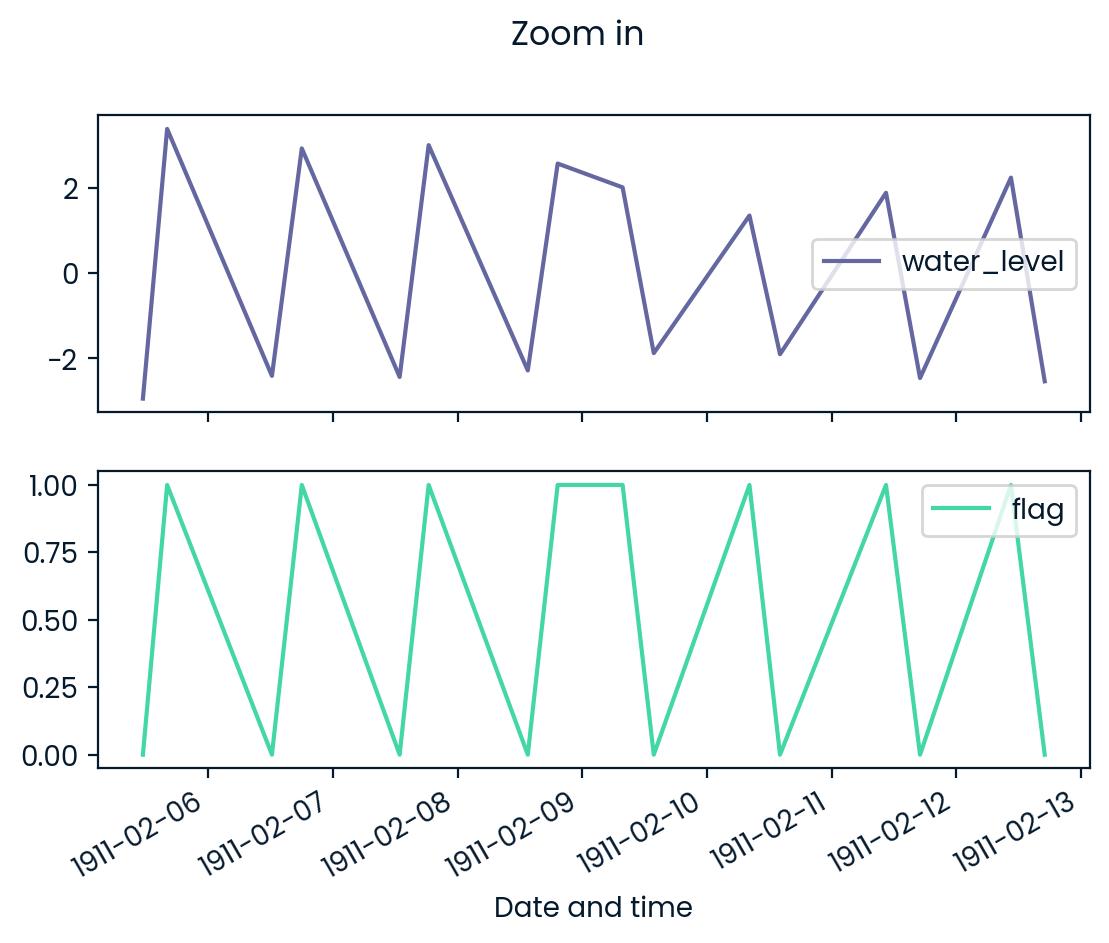

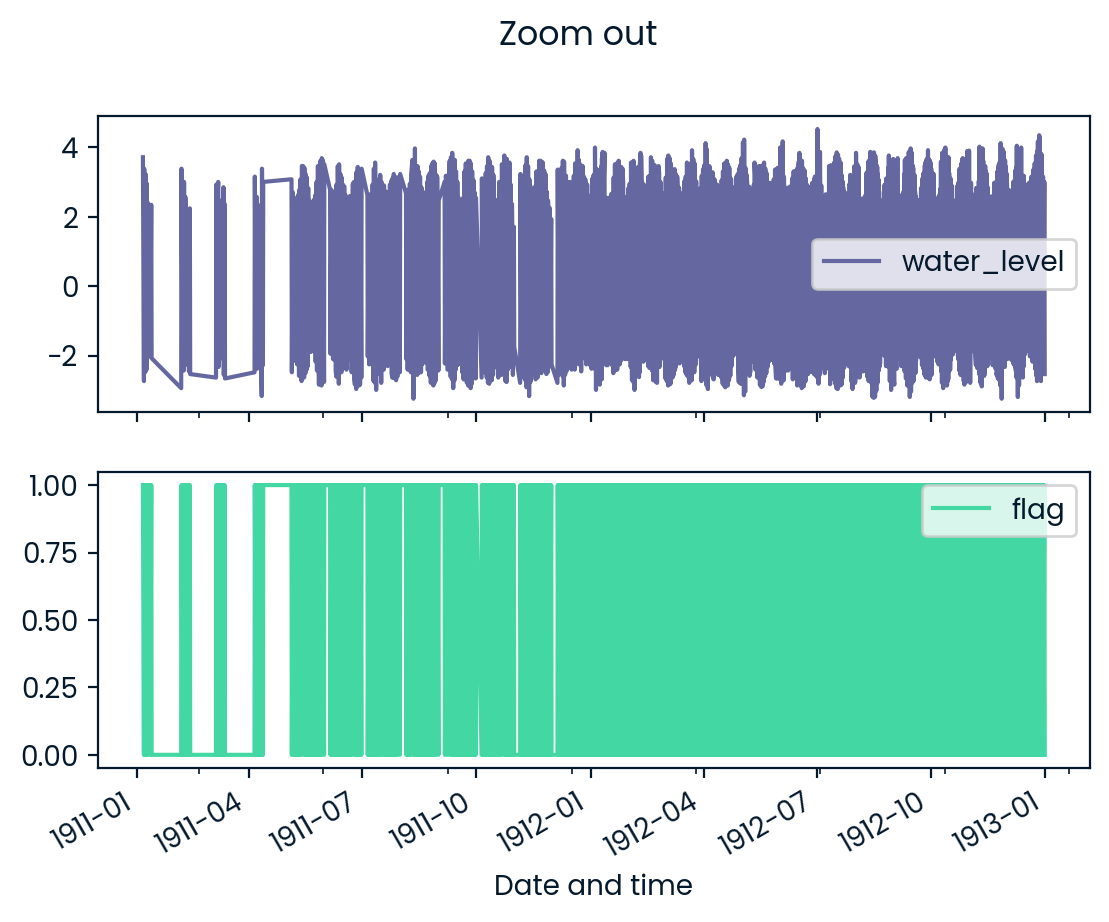

In [133]:
# Inspect the data
print(water_df.info())
print(water_df)
print('---------')
print('NaN values in the dataframe:\n',water_df.isna().sum())

# Plot the data to understant granularity 
water_df.loc['1911-02'].plot(subplots=True, title='Zoom in')
water_df.loc['1911':'1912'].plot(subplots=True, title='Zoom out')

In [134]:
# Now time to find the mean, median, and interquartile range for high- and low-tide data
descriptive_data = water_df.groupby('flag')['water_level'].agg([np.mean, np.median, IQR])
h_water_describe = descriptive_data.loc[1]
l_water_describe = descriptive_data.loc[0]
print('High water descriptive stats:\n',h_water_describe)
print('-------------------------------------------')
print('Low water descriptive stats:\n',l_water_describe)


High water descriptive stats:
 mean      3.318373
median    3.352600
IQR       0.743600
Name: 1, dtype: float64
-------------------------------------------
Low water descriptive stats:
 mean     -2.383737
median   -2.412900
IQR       0.538200
Name: 0, dtype: float64


In [135]:
# Create two new functions that will take a series anc calculate the 10th and 90th percentile 
def pct_above_quantile(series, q=0.90):
    threshold = series.quantile(q)
    return( series >= threshold).mean() * 100

def pct_below_quantile(series, q=0.10):
    threshold = series.quantile(q)
    return( series <= threshold).mean() * 100

high_water = water_df[water_df['flag']==1]
low_water = water_df[water_df['flag']==0]

high_ratio_alt = high_water.groupby(high_water.index.year)['water_level'].apply(pct_above_quantile).reset_index()
low_ratio_alt = low_water.groupby(low_water.index.year)['water_level'].apply(pct_below_quantile).reset_index()

In [136]:
solution = {
    "high_statistics": h_water_describe,   # Series with mean/median/IQR of high tide
    "low_statistics":  l_water_describe,   # Series with mean/median/IQR of low tide
    "very_high_ratio": high_ratio,         # DataFrame: year | very‑high‑tide %
    "very_low_ratio":  low_ratio           # DataFrame: year | very‑low‑tide %
}


In [137]:
# Package imports
import pandas as pd                

def IQR(column): 
    q25, q75 = column.quantile([0.25, 0.75])
    return q75-q25

# Load the data from London Bridge
lb = pd.read_csv('data/10-11_London_Bridge.txt') # Comma-separated .txt file

# Take only the first three columns
df = lb.iloc[:, :3]

# Rename columns
df.columns = ['datetime', 'water_level', 'is_high_tide']

# Convert to datetime
df['datetime'] = pd.to_datetime(df['datetime'])

# Convert to float
df['water_level'] = df.water_level.astype(float)

# Create extra month and year columns for easy access
df['month'] = df['datetime'].dt.month
df['year'] = df['datetime'].dt.year

# Filter df for high and low tide
tide_high = df[df['is_high_tide'] == 1]
tide_low = df[df['is_high_tide'] == 0]

# Create summary statistics
high_statistics = tide_high['water_level'].agg(['mean', 'median', IQR])
low_statistics = tide_low['water_level'].agg(['mean', 'median', IQR])

# Calculate ratio of high tide days
all_high_days = tide_high.groupby('year')['water_level'].count()
very_high_days = tide_high[tide_high['water_level'] > tide_high['water_level'].quantile(0.90)].groupby('year')['water_level'].count()
very_high_ratio = (very_high_days/all_high_days).reset_index()

# Calculate ratio of low tide days
all_low_days = tide_low.groupby('year')['water_level'].count()
very_low_days = tide_low[tide_low['water_level'] < tide_low['water_level'].quantile(0.10)].groupby('year')['water_level'].count()
very_low_ratio = (very_low_days/all_low_days).reset_index()

solution = {'high_statistics': high_statistics, 'low_statistics': low_statistics, 'very_high_ratio': very_high_ratio, 'very_low_ratio':very_low_ratio}
print(solution)

{'high_statistics': mean      3.318373
median    3.352600
IQR       0.743600
Name: water_level, dtype: float64, 'low_statistics': mean     -2.383737
median   -2.412900
IQR       0.538200
Name: water_level, dtype: float64, 'very_high_ratio':     year  water_level
0   1911     0.004098
1   1912     0.032316
2   1913     0.082212
3   1914     0.055313
4   1915     0.045045
..   ...          ...
80  1991     0.096317
81  1992     0.103253
82  1993     0.145923
83  1994     0.150355
84  1995     0.170213

[85 rows x 2 columns], 'very_low_ratio':     year  water_level
0   1911     0.060606
1   1912     0.066667
2   1913     0.022388
3   1914     0.039017
4   1915     0.033435
..   ...          ...
80  1991     0.150355
81  1992     0.107496
82  1993     0.112696
83  1994     0.106383
84  1995     0.107801

[85 rows x 2 columns]}
